# Caos I: la ecuación de Lorenz

## **Ejercicio 1)** Importando librerías

**1)** Importe las librerías `numpy` para operar con arrays, `scipy.signal` para analizar señales de datos y `matplotlib.pyplot` para graficar.

**2)** Suba el archivo "libreria" `ode.py` que fabricó en el práctico 4), e impórtelo.

In [2]:
# a)
import numpy as np
#import scipy as sp
import scipy.signal as sgn
#import scipy.linalg as linalg
import matplotlib.pyplot as plt

In [3]:
# b)
#import ode

def euler(f,x,t,h,p):
    """
    Calcula un paso de integración del método de Euler.

    Argumentos de entrada:

        f : R^n,R -> R^n
        x = x(t) : R^n
        t = tiempo : R
        h = paso de tiempo : R
        p = parametros : R^q

    Retorna aproximacion numérica de

        x(t+h) : R^n

    según el método de Euler.

    # Ejemplos:
    """
    return x+h*f(x,t,p)

def rk4(f,x,t,h,p):
    """
    Calcula un paso de integración del método de Runge Kutta orden 4.

    Argumentos de entrada:

        f : R^n -> R^n
        x = x(t) : R^n
        t = tiempo : R
        h = paso de tiempo : R
        p = parametros : R^q

    Retorna aproximacion numérica de

        x(t+h) : R^n

    según el método de Runge-Kutta de orden 4.

    # Ejemplos:
    """
    k1 = f(x,t,p)
    k2 = f(x+0.5*h*k1,t+0.5*h,p)
    k3 = f(x+0.5*h*k2,t+0.5*h,p)
    k4 = f(x+h*k3,t+h,p)
    return x+h*(k1+2.0*k2+2.0*k3+k4)/6.0

def integrador_ode(m,f,xa,a,b,k,p,c=lambda x,t,p:x):
    """
    Integra numéricamente la ODE

        dx/dt = f(x,t)

    sobre el intervalo t:[a,b] usando k pasos de integración y el método m, bajo condicion inicial x(a)=x0.
    No es necesario que a<b.

    Argumentos de entrada:

        m = metodo de integracion (ej. euler, rk2, etc.)
        f : R^n -> R^n
        xa = condicion inicial : R
        a = tiempo inicial : R
        b = tiempo final : R
        k = num. pasos de integracion : N
        p = parametros : R^q
        c = función condicionante : R^n,R,p -> R^n

    Retorna:

        t : R^{k+1} , t_j = a+j*h para j=0,1,...,k
        w : R^{n,k+1} , w_ij = x_i(t_j) para i=0,1,...,n-1 y j=0,1,...,k

    donde a+k*dt = b.
    """
    assert k>0
    n = len(xa)
    h = (b-a)/k
    w = np.zeros((n,k+1)) # Produce un array con forma y tipo especificada con los parametros,
                          # lleno de ceros. la forma puede ser espcificada con un entero o tupla (n,k+1)
    t = np.zeros(k+1)
    w[:,0] = xa           # actualiza la posicion inicial (columna de indice 0) de las variables con los valores
                          # de las condiciones iniciales
    t[0] = a              # actualiza la posicion cero con el valor del tiempo inicial

    for j in range(k):    #Aca se produce la iteración en j

        t[j+1] = t[j] + h                # iteracion tiempo
        w[:,j+1] = m(f,w[:,j],t[j],h,p)  # iteracion de w
        w[:,j+1] = c(w[:,j+1],t[j+1],p)  # condicion sobre w

    return t,w

## Ejercicio 2)

Considere el sistema de Ecuaciones Diferenciales Ordinarias de Lorenz

\begin{eqnarray}
\frac{dx}{dt} & = & s(y-x) \\
\frac{dy}{dt} & = & rx-y-xz \\
\frac{dz}{dt} & = & xy-bz
\end{eqnarray}

Sea $p=(s,r,b)$ el vector de parámetros.

**1)**
Usando el método de Runge-Kutta de orden 4, resuelva la ODE para las siguientes elecciones de las condiciones iniciales, de los parámetros y del intervalo de tiempo de integración:

&nbsp; &nbsp; **i)** $(x(0),y(0),z(0))=(1,0.5,0.1)$, $p=(10,0.5,8/3)$ y $t\in [0,10]$.

&nbsp; &nbsp; **ii)** $(x(0),y(0),z(0))=(1,0.5,0.1)$, $p=(10,10,8/3)$ y $t\in [0,20]$.

&nbsp; &nbsp; **iii)** $(x(0),y(0),z(0))=(1,0.5,0.1)$, $p=(10,28,8/3)$ y $t\in [0,50]$

**2)** Para cada caso calculado en el inciso **1)**, grafique, en un mismo gráfico, las curvas en función del tiempo $x(t)$ vs $t$, $y(t)$ vs $t$ y $z(t)$ vs $t$.

**3)**
Para cada caso calculado en el inciso **1)**, grafique paramétricamente en función del tiempo, y en 3 dimensiones, el vector que describe la trayectoria de la solución, i.e. grafique $(x(t),y(t),z(t))$ vs $t$.

In [4]:
# 2.1)

# Definimos sistema de Lorenz
def lorenz_ode(estado, t, p):
    x, y, z = estado
    s, r, b = p

    dx = s * (y - x)
    dy = r * x - y - x * z
    dz = x * y - b * z
    return np.array([dx, dy, dz])

# Condición inicial común a los tres casos
xa = np.array([1.0, 0.5, 0.1])
h = 0.01  # Paso de integración

# Definimos los 3 casos: (etiqueta, parámetros p, t_inicial, t_final)
casos_lorenz = [
    ("Caso i) r = 0.5 (Decaimiento al origen)",   (10.0, 0.5, 8.0/3.0), 0.0, 10.0),
    ("Caso ii) r = 10 (Espiral a punto fijo)",     (10.0, 10.0, 8.0/3.0), 0.0, 20.0),
    ("Caso iii) r = 28 (Régimen caótico)",         (10.0, 28.0, 8.0/3.0), 0.0, 50.0)
]

# Resolvemos los 3 casos y guardamos los resultados
resultados = []
for titulo, p, a, b_t in casos_lorenz:
    k = int((b_t - a) / h)
    t, w = integrador_ode(rk4, lorenz_ode, xa, a, b_t, k, p)
    resultados.append((titulo, t, w))

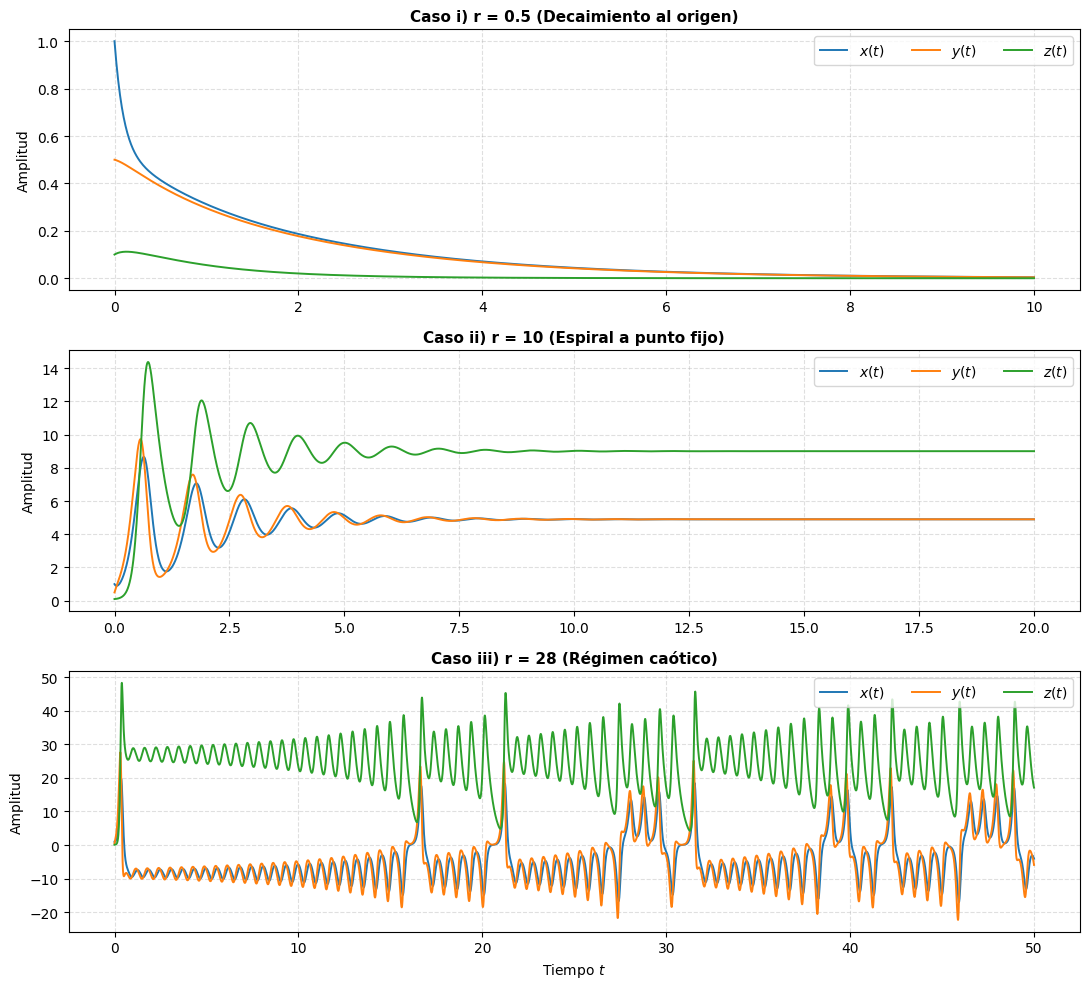

In [5]:
#2.2
fig, axes = plt.subplots(3, 1, figsize=(11, 10))

for idx, (titulo, t, w) in enumerate(resultados):
    ax = axes[idx]
    x, y, z = w[0], w[1], w[2]

    ax.plot(t, x, label='$x(t)$', color='#1f77b4', lw=1.4)
    ax.plot(t, y, label='$y(t)$', color='#ff7f0e', lw=1.4)
    ax.plot(t, z, label='$z(t)$', color='#2ca02c', lw=1.4)

    ax.set_title(titulo, fontsize=11, fontweight='bold')
    ax.set_ylabel('Amplitud')
    ax.grid(True, linestyle='--', alpha=0.4)
    ax.legend(loc='upper right', ncol=3)

axes[-1].set_xlabel('Tiempo $t$')
plt.tight_layout()
plt.show()

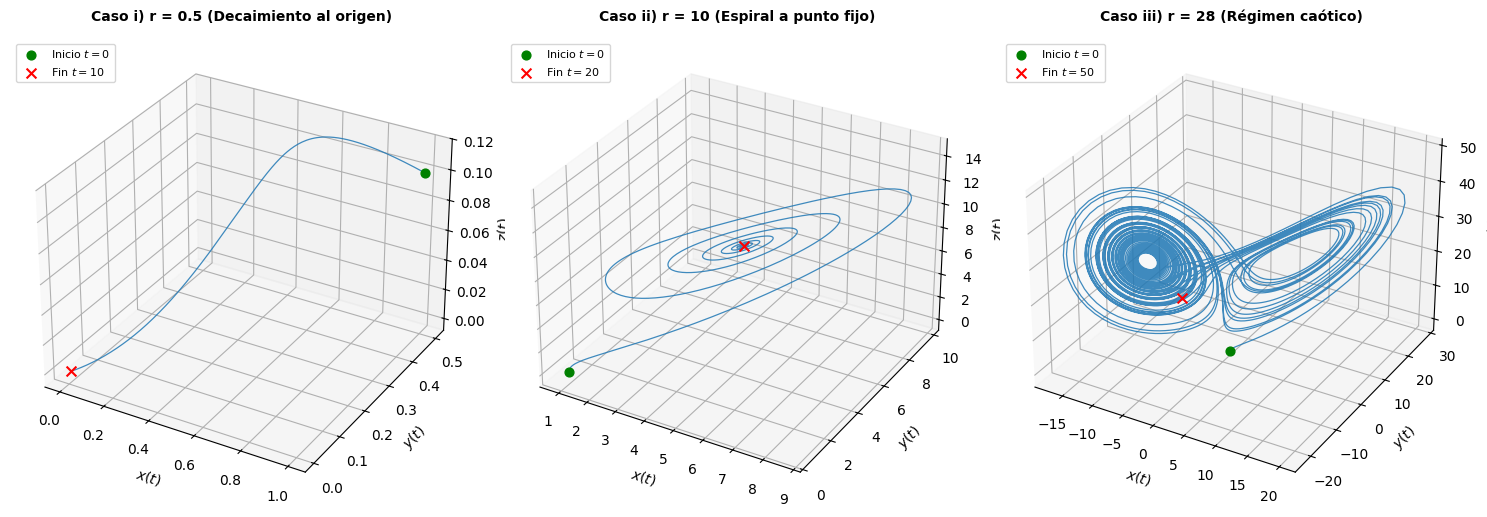

In [6]:
#2.3

fig = plt.figure(figsize=(15, 5))

for idx, (titulo, t, w) in enumerate(resultados):
    ax = fig.add_subplot(1, 3, idx + 1, projection='3d')
    x, y, z = w[0], w[1], w[2]

    # Curva paramétrica en 3D
    ax.plot(x, y, z, color='#1f77b4', lw=0.9, alpha=0.85)

    # Marcadores de inicio y fin de la trayectoria
    ax.scatter(x[0], y[0], z[0], color='green', s=40, label='Inicio $t=0$')
    ax.scatter(x[-1], y[-1], z[-1], color='red', marker='x', s=50, label=f'Fin $t={t[-1]:.0f}$')

    ax.set_title(titulo, fontsize=10, fontweight='bold', pad=12)
    ax.set_xlabel('$x(t)$')
    ax.set_ylabel('$y(t)$')
    ax.set_zlabel('$z(t)$')
    ax.legend(loc='upper left', fontsize=8)

plt.tight_layout()
plt.show()

## Ejercicio 3)

**1)** Repita el caso **1.iii)** del ejercicio **2)**, para $t\in [0,300]$, y eliminando el transiente que se observa antes de "converger" al atractor.

**2)** Identifique los máximos locales de la curva $z(t)$ obtenida en el inciso **1)**, y enumérelos como $z_1,z_2,...,z_i,...,z_n$.

**3)** Grafique $z_{i+1}$ vs $z_i$ para todo $i\in\{1,2,...,n-1\}$.

Total de máximos locales detectados (sin transiente): n = 358


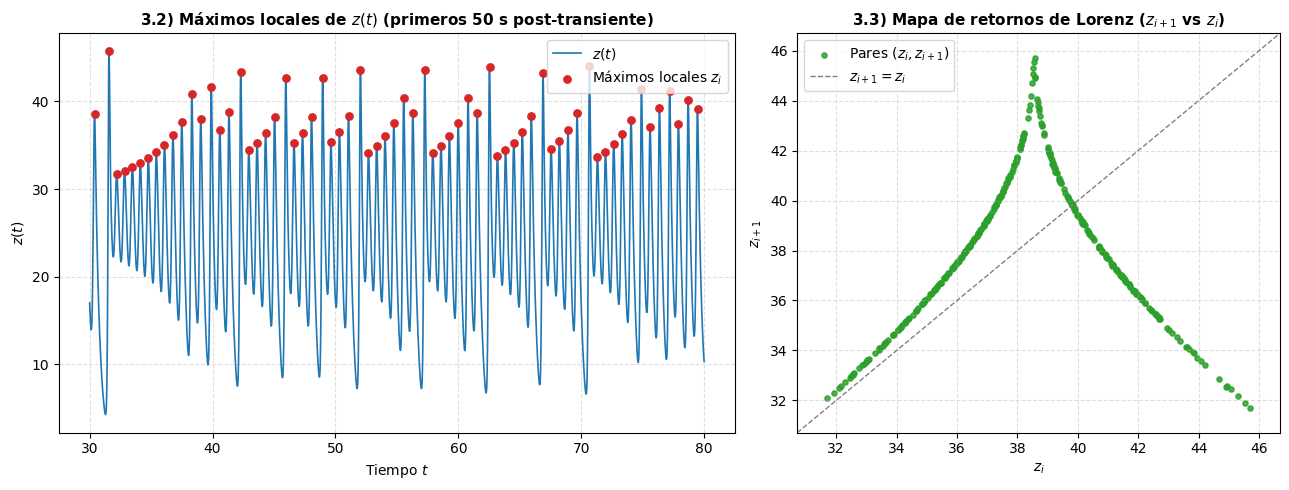

In [7]:
# 3.1) Integración en t ∈ [0, 300] para el caso caótico p = (10, 28, 8/3)
xa = np.array([1.0, 0.5, 0.1])
p_caos = (10.0, 28.0, 8.0 / 3.0)
a, b_t = 0.0, 300.0
h = 0.01
k = int((b_t - a) / h)

t, w = integrador_ode(rk4, lorenz_ode, xa, a, b_t, k, p_caos)

# Eliminamos el transiente inicial (descartamos t < 30)
t_transiente = 30.0
idx_estacionario = np.where(t >= t_transiente)[0]

t_est = t[idx_estacionario]
z_est = w[2, idx_estacionario]

# 3.2) Identificamos los máximos locales de z(t) usando scipy.signal (sgn)
indices_picos, _ = sgn.find_peaks(z_est)
t_picos = t_est[indices_picos]
z_picos = z_est[indices_picos]  # z_1, z_2, ..., z_n

print(f"Total de máximos locales detectados (sin transiente): n = {len(z_picos)}")

# 3.3) Visualización: serie z(t) con sus máximos y mapa de retornos z_{i+1} vs z_i
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={'width_ratios': [1.4, 1]})

# Panel izquierdo: fragmento de z(t) mostrando los máximos locales z_i
muestra = t_est <= 80.0
ax1.plot(t_est[muestra], z_est[muestra], color='#1f77b4', lw=1.2, label='$z(t)$')
muestra_picos = t_picos <= 80.0
ax1.scatter(t_picos[muestra_picos], z_picos[muestra_picos], color='#d62728', s=28, zorder=3, label='Máximos locales $z_i$')
ax1.set_title('3.2) Máximos locales de $z(t)$ (primeros 50 s post-transiente)', fontsize=11, fontweight='bold')
ax1.set_xlabel('Tiempo $t$')
ax1.set_ylabel('$z(t)$')
ax1.grid(True, linestyle='--', alpha=0.4)
ax1.legend()

# Panel derecho: Mapa de retornos de Lorenz (z_{i+1} vs z_i)
z_i = z_picos[:-1]
z_i_mas_1 = z_picos[1:]

ax2.scatter(z_i, z_i_mas_1, s=14, color='#2ca02c', alpha=0.85, label='Pares $(z_i, z_{i+1})$')

# Línea identidad z_{i+1} = z_i como referencia visual
lim_min, lim_max = z_picos.min() - 1, z_picos.max() + 1
ax2.plot([lim_min, lim_max], [lim_min, lim_max], color='gray', linestyle='--', lw=1, label='$z_{i+1} = z_i$')

ax2.set_title('3.3) Mapa de retornos de Lorenz ($z_{i+1}$ vs $z_i$)', fontsize=11, fontweight='bold')
ax2.set_xlabel('$z_i$')
ax2.set_ylabel('$z_{i+1}$')
ax2.set_xlim(lim_min, lim_max)
ax2.set_ylim(lim_min, lim_max)
ax2.grid(True, linestyle='--', alpha=0.4)
ax2.legend()

plt.tight_layout()
plt.show()

## Ejercicio 4)

**1)** Con la intención de imitar un set de datos, agregue ruido Gaussiano de varianza $\sigma^2=1$ a la curva $z(t)$ vs $t$ generada en el inciso **1)** del ejercicio **3)**. Llamaremos a esta nueva curva $\tilde{z}(t)$ vs $t$. Grafíquela.

**2)** Utilice algún algoritmo de suavizado de curvas (ver función `savgol_filter` de la librería `scipy.signal`) para suavizar $\tilde{z}(t)$ vs $t$. Llame $\hat{z}(t)$ vs $t$ a la curva suavizada.

**3)** Utilice la curva suavizada del inciso **2)** para identificar los tiempos $\hat{t}_1$,$\hat{t}_2$,...,$\hat{t}_n$ en los cuales ocurre los máximos locales $\hat{z}_1=\hat{z}(\hat{t}_1)$, $\hat{z}_2=\hat{z}(\hat{t}_2)$, ...,$\hat{z}_n=\hat{z}(\hat{t}_n)$ correspondientes.

Calcule además los valores de la curva sin suavizar en dichos tiempos, i.e. calcule $\tilde{z}_1=\tilde{z}(\hat{t_1})$, $\tilde{z}_2=\tilde{z}(\hat{t_2})$, ..., $\tilde{z}_n=\tilde{z}(\hat{t_n})$.

**4)** Grafique la curva suavizada $\tilde{z}(t)$ vs $t$.

Agregue al gráfico los máximos $(\tilde{z}_i,\hat{t}_i)$ con puntos azules, y los máximos $(\hat{z}_i,\hat{t}_i)$ con puntos rojos.

Que observa?

**5)** Grafique $\tilde{z}_{i+1}$ vs $\tilde{z}_i$ para todo $i\in\{1,2,...,n-1\}$.

**6)** Grafique $\hat{z}_{i+1}$ vs $\hat{z}_i$ para todo $i\in\{1,2,...,n-1\}$.

**7)** Comparando los resultados de los incisos **5)** y **6)** con los del gráfico del inciso **3)** del ejercicio **3)**.

Discuta y comente.

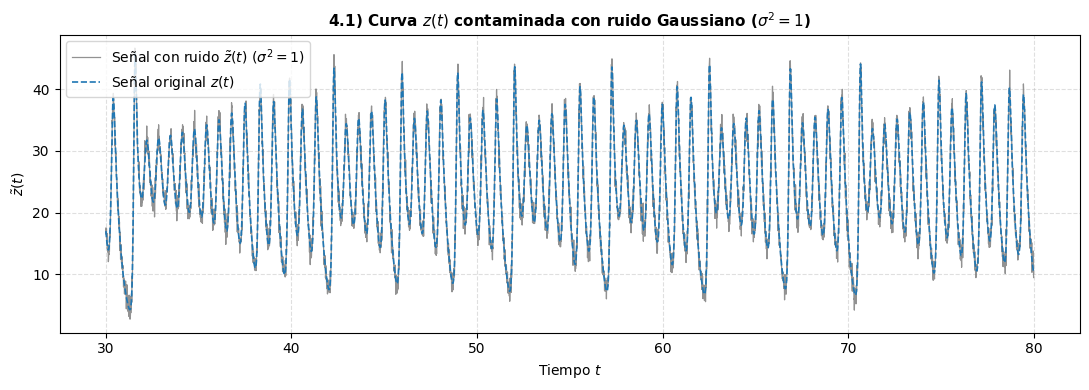

In [8]:
# 4.1) Agregamos ruido Gaussiano de varianza sigma^2 = 1 (sigma = 1.0) a z_est
np.random.seed(42)
sigma = 1.0
ruido = np.random.normal(loc=0.0, scale=sigma, size=len(z_est))
z_tilde = z_est + ruido

# Graficamos la señal ruidosa z_tilde(t) (mostramos un tramo para apreciar el ruido)
fig, ax = plt.subplots(figsize=(11, 4))
tramo = t_est <= 80.0
ax.plot(t_est[tramo], z_tilde[tramo], color='#7f7f7f', lw=0.9, alpha=0.85, label=r'Señal con ruido $\tilde{z}(t)$ ($\sigma^2=1$)')
ax.plot(t_est[tramo], z_est[tramo], color='#1f77b4', lw=1.2, linestyle='--', label=r'Señal original $z(t)$')
ax.set_title(r'4.1) Curva $z(t)$ contaminada con ruido Gaussiano ($\sigma^2 = 1$)', fontsize=11, fontweight='bold')
ax.set_xlabel('Tiempo $t$')
ax.set_ylabel(r'$\tilde{z}(t)$')
ax.grid(True, linestyle='--', alpha=0.4)
ax.legend()
plt.tight_layout()
plt.show()

In [9]:
# 4.2) Suavizado con filtro de Savitzky-Golay (window_length impar, polyorder=3)
# Con paso h = 0.01, una ventana de 51 puntos equivale a 0.5 s (suaviza el ruido sin achatar los picos)
window_length = 51
polyorder = 3
z_hat = sgn.savgol_filter(z_tilde, window_length=window_length, polyorder=polyorder)

# 4.3) Identificamos los máximos locales sobre la curva suavizada z_hat(t)
idx_hat, _ = sgn.find_peaks(z_hat, distance=20)

t_hat_picos = t_est[idx_hat]       # Tiempos \hat{t}_1, ..., \hat{t}_n
z_hat_picos = z_hat[idx_hat]       # Máximos suavizados \hat{z}_1, ..., \hat{z}_n
z_tilde_picos = z_tilde[idx_hat]   # Valores sin suavizar \tilde{z}(\hat{t}_1), ..., \tilde{z}(\hat{t}_n)

print(f"Máximos detectados en la curva suavizada: n = {len(z_hat_picos)}")

Máximos detectados en la curva suavizada: n = 385


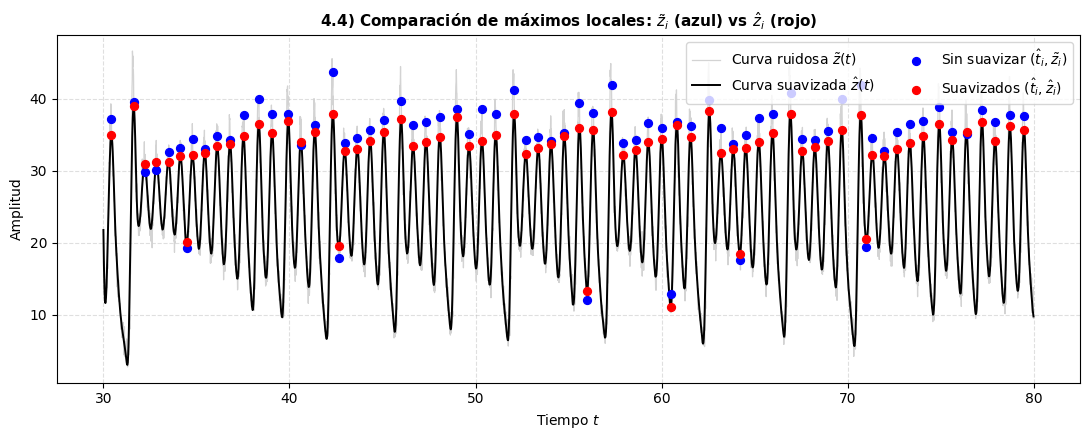

In [10]:
# 4.4) Gráfico comparativo de máximos sobre la curva suavizada y ruidosa
fig, ax = plt.subplots(figsize=(11, 4.5))
tramo = t_est <= 80.0
tramo_picos = t_hat_picos <= 80.0

ax.plot(t_est[tramo], z_tilde[tramo], color='lightgray', lw=0.9, label=r'Curva ruidosa $\tilde{z}(t)$')
ax.plot(t_est[tramo], z_hat[tramo], color='black', lw=1.4, label=r'Curva suavizada $\hat{z}(t)$')

# Puntos azules: (\hat{t}_i, \tilde{z}_i) | Puntos rojos: (\hat{t}_i, \hat{z}_i)
ax.scatter(t_hat_picos[tramo_picos], z_tilde_picos[tramo_picos], color='blue', s=32, zorder=4, label=r'Sin suavizar $(\hat{t}_i, \tilde{z}_i)$')
ax.scatter(t_hat_picos[tramo_picos], z_hat_picos[tramo_picos], color='red', s=32, zorder=5, label=r'Suavizados $(\hat{t}_i, \hat{z}_i)$')

ax.set_title(r'4.4) Comparación de máximos locales: $\tilde{z}_i$ (azul) vs $\hat{z}_i$ (rojo)', fontsize=11, fontweight='bold')
ax.set_xlabel('Tiempo $t$')
ax.set_ylabel('Amplitud')
ax.grid(True, linestyle='--', alpha=0.4)
ax.legend(loc='upper right', ncol=2)
plt.tight_layout()
plt.show()

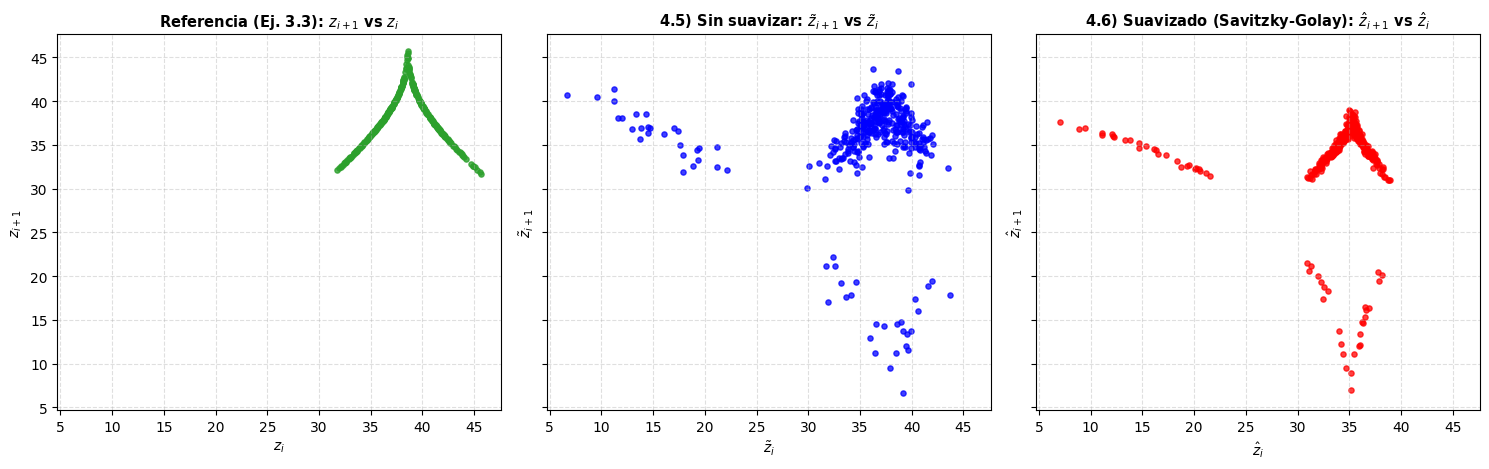

In [11]:
# 4.5) y 4.6) Mapas de retornos: sin suavizar vs suavizado (comparados con el original)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharex=True, sharey=True)

# Referencia del Ejercicio 3.3
axes[0].scatter(z_picos[:-1], z_picos[1:], s=14, color='#2ca02c', alpha=0.8)
axes[0].set_title('Referencia (Ej. 3.3): $z_{i+1}$ vs $z_i$', fontsize=10.5, fontweight='bold')
axes[0].set_xlabel('$z_i$')
axes[0].set_ylabel('$z_{i+1}$')

# 4.5) Mapa de retornos evaluado en la señal con ruido \tilde{z}_i
axes[1].scatter(z_tilde_picos[:-1], z_tilde_picos[1:], s=14, color='blue', alpha=0.75)
axes[1].set_title(r'4.5) Sin suavizar: $\tilde{z}_{i+1}$ vs $\tilde{z}_i$', fontsize=10.5, fontweight='bold')
axes[1].set_xlabel(r'$\tilde{z}_i$')
axes[1].set_ylabel(r'$\tilde{z}_{i+1}$')

# 4.6) Mapa de retornos evaluado en la señal suavizada \hat{z}_i
axes[2].scatter(z_hat_picos[:-1], z_hat_picos[1:], s=14, color='red', alpha=0.75)
axes[2].set_title(r'4.6) Suavizado (Savitzky-Golay): $\hat{z}_{i+1}$ vs $\hat{z}_i$', fontsize=10.5, fontweight='bold')
axes[2].set_xlabel(r'$\hat{z}_i$')
axes[2].set_ylabel(r'$\hat{z}_{i+1}$')

for ax in axes:
    ax.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

**Discusión:** Bla bla bla...